# 2D Diffusion and Heterogeneous Diffusion $D(x)$

**References:** `Notes/problem_set_III.pdf` (Q2, Q3), `Notes/Quiz2/03_2D_and_Heterogeneous_Diffusion.ipynb`

## Concept, Formulas & Stability
- **2D Diffusion Equation:**
  $$\frac{\partial \rho}{\partial t} = D \left(\frac{\partial^2 \rho}{\partial x^2} + \frac{\partial^2 \rho}{\partial y^2}\right)$$
  When $\Delta x = \Delta y = \delta$, FTCS stability requires:
  $$C = \frac{D \Delta t}{\delta^2} \le \frac{1}{4} \qquad \left(\text{in } d\text{ dimensions: } \frac{D\Delta t}{\delta^2} \le \frac{1}{2d}\right)$$
- **Heterogeneous Diffusion ($D$ varies with $x$):**
  $$\frac{\partial \rho}{\partial t} = \frac{\partial}{\partial x}\left(D(x)\frac{\partial \rho}{\partial x}\right)$$
  Use conservative half-grid fluxes $J_{i+1/2} = -D_{i+1/2}\frac{\rho_{i+1} - \rho_i}{\Delta x}$ with $D_{i+1/2} = \frac{D_i + D_{i+1}}{2}$.
  Stability limit: $\max(D)\frac{\Delta t}{\Delta x^2} \le \frac{1}{2}$.
- **Limitations:** 2D explicit FTCS has a stricter $\Delta t$ limit ($1/4$ instead of $1/2$). In heterogeneous diffusion, using $D_{\max}$ keeps the scheme stable everywhere.

*Professor code: None provided separately (follows the Quiz 2 Reference code).*

2D Courant number C = 0.20 (Must be <= 0.25)


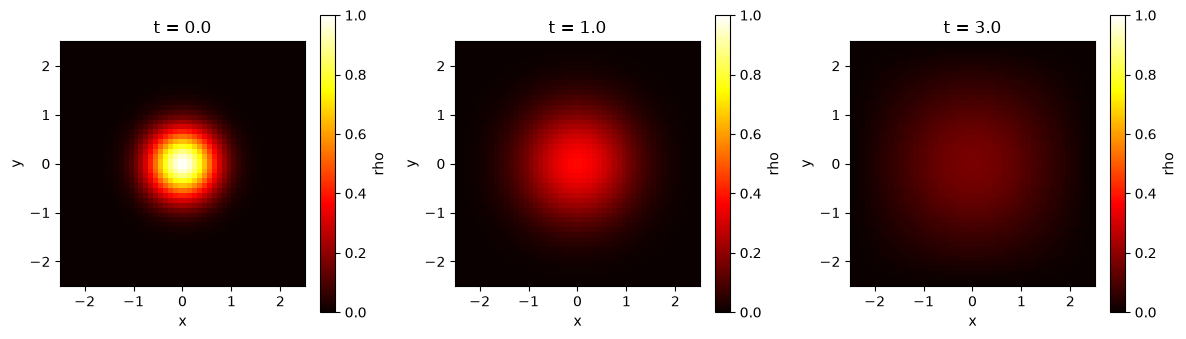

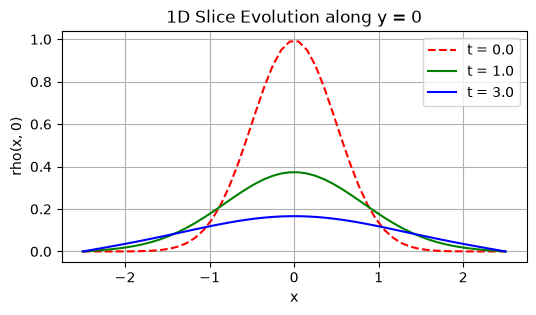

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Part 1: 2D Diffusion Evolution (C = 0.20 <= 0.25)
Nx, Ny = 50, 50
delta = 0.1
D = 0.2
dt = 0.01
C = D * dt / (delta**2)
print(f"2D Courant number C = {C:.2f} (Must be <= 0.25)")
assert C <= 0.25

x = np.linspace(-2.5, 2.5, Nx)
y = np.linspace(-2.5, 2.5, Ny)
X, Y = np.meshgrid(x, y)

rho = np.exp(-(X**2 + Y**2) / 0.5)
rho_0 = rho.copy()

# Evolve to t = 1.0 (100 steps)
for n in range(100):
    rho[1:-1, 1:-1] += C * (rho[2:, 1:-1] + rho[:-2, 1:-1] + rho[1:-1, 2:] + rho[1:-1, :-2] - 4 * rho[1:-1, 1:-1])
rho_1 = rho.copy()

# Evolve to t = 3.0 (200 more steps)
for n in range(200):
    rho[1:-1, 1:-1] += C * (
        rho[2:, 1:-1] + rho[:-2, 1:-1] +
        rho[1:-1, 2:] + rho[1:-1, :-2] - 4 * rho[1:-1, 1:-1]
    )
rho_2 = rho.copy()

# Plot 3 timestamps
plt.figure(figsize=(12, 3.5))

plt.subplot(1, 3, 1)
plt.imshow(rho_0, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot', vmin=0, vmax=1)
plt.colorbar(label='rho'); plt.title('t = 0.0'); plt.xlabel('x'); plt.ylabel('y')

plt.subplot(1, 3, 2)
plt.imshow(rho_1, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot', vmin=0, vmax=1)
plt.colorbar(label='rho'); plt.title('t = 1.0'); plt.xlabel('x'); plt.ylabel('y')

plt.subplot(1, 3, 3)
plt.imshow(rho_2, extent=[-2.5, 2.5, -2.5, 2.5], origin='lower', cmap='hot', vmin=0, vmax=1)
plt.colorbar(label='rho'); plt.title('t = 3.0'); plt.xlabel('x'); plt.ylabel('y')

plt.tight_layout()
plt.show()

# 1D Cross-section along y = 0
plt.figure(figsize=(6, 3))
mid = Ny // 2
plt.plot(x, rho_0[mid, :], 'r--', label='t = 0.0')
plt.plot(x, rho_1[mid, :], 'g-', label='t = 1.0')
plt.plot(x, rho_2[mid, :], 'b-', label='t = 3.0')
plt.xlabel('x'); plt.ylabel('rho(x, 0)')
plt.title('1D Slice Evolution along y = 0')
plt.legend(); plt.grid(True)
plt.show()

## Heterogeneous Diffusion ($D$ varies with $x$)
- **Heterogeneous Diffusion Equation:**
  $$\frac{\partial \rho}{\partial t} = \frac{\partial}{\partial x}\left(D(x)\frac{\partial \rho}{\partial x}\right)$$
- **Conservative Half-Grid Fluxes:**
  $$J_{i+1/2} = -D_{i+1/2}\frac{\rho_{i+1} - \rho_i}{\Delta x} \qquad \text{with} \qquad D_{i+1/2} = \frac{D_i + D_{i+1}}{2}$$
- **Stability & Limitations:** $\max(D)\frac{\Delta t}{\Delta x^2} \le \frac{1}{2}$. Using $D_{\max}$ keeps the scheme stable everywhere.

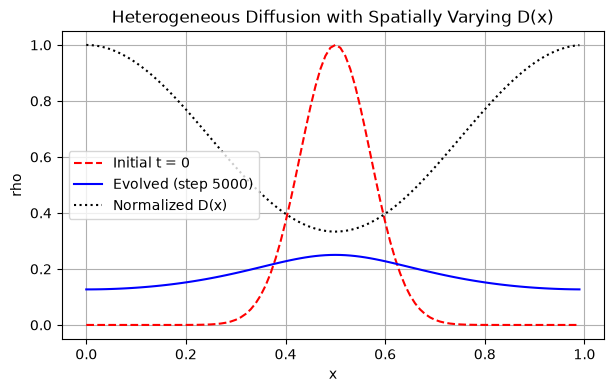

In [2]:
# Part 2: Heterogeneous Diffusion with spatially varying D(x)
N = 100
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
dt = 0.0001

D_x = 0.1 * (1.0 + 0.5 * np.cos(2 * np.pi * x / L))
D_half = 0.5 * (D_x + np.roll(D_x, -1))

assert np.max(D_x) * dt / (dx**2) <= 0.5

rho = np.exp(-100 * (x - 0.5)**2)
rho_0 = rho.copy()

for step in range(5000):
    flux = -D_half * (np.roll(rho, -1) - rho) / dx
    rho = rho - (dt / dx) * (flux - np.roll(flux, 1))

plt.figure(figsize=(7, 4))
plt.plot(x, rho_0, 'r--', label='Initial t = 0')
plt.plot(x, rho, 'b-', label='Evolved (step 5000)')
plt.plot(x, D_x / np.max(D_x), 'k:', label='Normalized D(x)')
plt.title('Heterogeneous Diffusion with Spatially Varying D(x)')
plt.xlabel('x'); plt.ylabel('rho')
plt.legend(); plt.grid(True)
plt.show()